# Изучение рынка заведений общественного питания Москвы

- Автор: Исмагилов Самат


### Цели и задачи проекта

**Цель проекта:** Провести исследовательский анализ рынка общественного питания в Москве на основе данных с Яндекс Карт. Выявить ключевые закономерности, влияющие на успех заведений, и сформулировать рекомендации для заказчика.

**Задачи:**
1. Загрузить и выполнить предобработку данных.
2. Исследовать структуру рынка: категории заведений, распределение по районам и соотношение сетевых/несетевых игроков.
3. Проанализировать количественные показатели: посадочные места, рейтинги и средний чек.
4. Выявить взаимосвязи в данных и определить топ-15 популярных сетей.
5. На основе анализа сформулировать итоговые выводы и практические рекомендации.

### Описание данных

В проекте используются два набора данных в формате CSV:

1. **`/datasets/rest_info.csv`** — содержит основную информацию о заведениях:
   - `id`, `name`, `address`, `district`, `category` — уникальный идентификатор и текстовые характеристики заведения.
   - `hours` — режим работы.
   - `rating` — рейтинг по оценкам пользователей (макс. 5.0).
   - `chain` — статус сетевого заведения (0 или 1).
   - `seats` — количество посадочных мест.

2. **`/datasets/rest_price.csv`** — содержит информацию о ценах:
   - `price` — категория цен.
   - `avg_bill` — текстовое описание среднего чека.
   - `middle_avg_bill` — число, отражающее медиану среднего чека.
   - `middle_coffee_cup` — число, отражающее медиану стоимости одной чашки капучино.

Данные объединяются по общему столбцу `id`.

### Содержимое проекта

Проект состоит из четырех последовательных этапов:

**Шаг 1. Загрузка и знакомство с данными**
- Загрузка двух датафреймов (`rest_info` и `rest_price`).
- Первичное изучение структуры, типов данных и объема.
- Объединение таблиц в единый датафрейм `data`.

**Шаг 2. Предобработка данных**
- Корректировка типов данных (при необходимости).
- Анализ и обработка пропущенных значений.
- Нормализация текста и удаление дубликатов.
- Создание нового признака `is_24_7` для круглосуточных заведений.

**Шаг 3. Исследовательский анализ данных**
- Анализ категорий заведений и их распределения по административным округам.
- Оценка соотношения сетевых и несетевых заведений.
- Исследование посадочных мест: поиск выбросов и расчет медианных значений.
- Анализ рейтингов, корреляционный анализ и выделение топ-15 сетей.
- Изучение вариации среднего чека в зависимости от района Москвы.

**Шаг 4. Итоговый вывод и рекомендации**
- Обобщение результатов аналитики.
- Формулировка ключевых выводов по рынку Москвы.
- Разработка практических рекомендаций для потенциальных заказчиков.

## 1. Загрузка данных и знакомство с ними

- Загрузим данные о заведениях общественного питания Москвы.

In [1]:
import pandas as pd

In [2]:
!pip install phik -U
from phik import phik_matrix

In [3]:
rest_info = pd.read_csv('/datasets/rest_info.csv')

In [4]:
rest_price = pd.read_csv('/datasets/rest_price.csv')

- Познакомимся с данными и изучим общую информацию о них.

In [5]:
rest_info.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        8406 non-null   object 
 1   name      8406 non-null   object 
 2   category  8406 non-null   object 
 3   address   8406 non-null   object 
 4   district  8406 non-null   object 
 5   hours     7870 non-null   object 
 6   rating    8406 non-null   float64
 7   chain     8406 non-null   int64  
 8   seats     4795 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 591.2+ KB


In [6]:
rest_price.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4058 non-null   object 
 1   price              3315 non-null   object 
 2   avg_bill           3816 non-null   object 
 3   middle_avg_bill    3149 non-null   float64
 4   middle_coffee_cup  535 non-null    float64
dtypes: float64(2), object(3)
memory usage: 158.6+ KB


In [7]:
display(rest_info.head())
display(rest_price.head())

,id,name,category,address,district,hours,rating,chain,seats
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0


,id,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,045780ada3474c57a2112e505d74b633,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
1,1070b6b59144425896c65889347fcff6,средние,Средний счёт:от 1000 ₽,1000.0,NaN
2,03ac7cd772104f65b58b349dc59f03ee,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
3,a163aada139c4c7f87b0b1c0b466a50f,средние,Средний счёт:400–600 ₽,500.0,NaN
4,8a343546b24e4a499ad96eb7d0797a8a,средние,NaN,NaN,NaN


### Промежуточный вывод по данным

**1. Объем данных и соответствие описанию:**
*   Датасет `rest_info` содержит **8406 строк** и 9 столбцов. 
*   Датасет `rest_price` содержит **4058 строк** и 5 столбцов.
*   Структура таблиц полностью соответствует описанию, представленному в задании. Ключом для объединения является столбец `id`.

**2. Типы данных:**
*   В таблице `rest_info`: Большинство столбцов имеют тип `object`, что корректно для названий, адресов и категорий. Столбец `chain` имеет тип `int64` (содержит 0 и 1), а `rating` — `float64`. Это верные типы.
*   В таблице `rest_price`: Столбцы `price` и `avg_bill` имеют тип `object`, так как содержат текстовые данные. Столбцы `middle_avg_bill` и `middle_coffee_cup` имеют тип `float64`, что также соответствует их будущему числовому содержанию.

**3. Пропущенные значения:**
*   **`rest_info`:** Столбцы `name`, `address`, `category`, `district`, `rating`, `chain` заполнены полностью. Однако обнаружены пропуски в столбцах `hours` и `seats`.
*   **`rest_price`:** В этом датасете пропусков значительно больше. Столбец `price` имеет пропуски. Столбец `middle_avg_bill` заполнен у 3149 записей, а `middle_coffee_cup` — всего у 535. Это указывает на то, что данные о ценах и среднем чеке представлены не для всех заведений.

**4. Особенности данных, на которые стоит обратить внимание при предобработке:**
1.  **Разный объем данных:** Количество записей в `rest_info` (8406) почти в два раза превышает количество записей в `rest_price` (4058). При объединении таблиц по `id` значительная часть заведений не будет иметь информации о ценах.
2.  **Сложность столбца `hours`:** Режим работы записан в виде произвольного текста. Для создания признака `is_24_7` потребуется его очистка и парсинг.
3.  **Сложность столбца `avg_bill`:** Содержит текстовые диапазоны и описания. Для извлечения числовых значений `middle_avg_bill` и `middle_coffee_cup` потребуется написать специальную функцию, которая будет рассчитывать медиану из диапазонов, как указано в инструкции.
4.  **Критичные пропуски:** Из-за большого количества пропусков в `seats` и в ценовых показателях, при анализе этих признаков стоит помнить о риске смещения выборки.

### Подготовка единого датафрейма

- Объединим данные двух датасетов в один.

In [8]:
data = pd.merge(rest_info, rest_price, on='id', how='outer')

In [9]:
print(data.shape)

(8406, 13)


In [10]:
temp = data.copy() 
len(temp)

8406

## 2. Предобработка данных

Подготовим данные к исследовательскому анализу:

- Изучим корректность типов данных и при необходимости проведем их преобразование.

In [11]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8406 non-null   object 
 1   name               8406 non-null   object 
 2   category           8406 non-null   object 
 3   address            8406 non-null   object 
 4   district           8406 non-null   object 
 5   hours              7870 non-null   object 
 6   rating             8406 non-null   float64
 7   chain              8406 non-null   int64  
 8   seats              4795 non-null   float64
 9   price              3315 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    3149 non-null   float64
 12  middle_coffee_cup  535 non-null    float64
dtypes: float64(4), int64(1), object(8)
memory usage: 919.4+ KB


- Изучим пропущенные значения в данных: посчитаем их количество в каждом столбце датафрейме, изучим данные с пропущенными значениями и предположим гипотезы их появления. Проведем обработку пропущенных значений.

In [12]:
missing_values = data.isnull().sum()
print('Количество пропусков в каждом столбце:')
print(missing_values)

missing_percent = (data.isnull().sum() / len(data)) * 100
print('\nДоля пропусков в процентах:')
print(missing_percent)

Количество пропусков в каждом столбце:
id                      0
name                    0
category                0
address                 0
district                0
hours                 536
rating                  0
chain                   0
seats                3611
price                5091
avg_bill             4590
middle_avg_bill      5257
middle_coffee_cup    7871
dtype: int64

Доля пропусков в процентах:
id                    0.000000
name                  0.000000
category              0.000000
address               0.000000
district              0.000000
hours                 6.376398
rating                0.000000
chain                 0.000000
seats                42.957411
price                60.563883
avg_bill             54.603854
middle_avg_bill      62.538663
middle_coffee_cup    93.635498
dtype: float64


In [13]:
def show_missing_stats(tmp0):
    """
    Функция для отображения статистики пропущенных значений в DataFrame.
    """
    missing_stats = pd.DataFrame({
        'Кол-во пропусков': tmp0.isnull().sum(),
        'Доля пропусков': tmp0.isnull().mean()
    })
    missing_stats = missing_stats[missing_stats['Кол-во пропусков'] > 0]
    
    if missing_stats.empty:
        return "Пропусков в данных нет"
    
    return (missing_stats.style.format({'Доля пропусков': '{:.4f}'}).background_gradient(cmap='coolwarm'))
show_missing_stats(data)

,Кол-во пропусков,Доля пропусков
hours,536,0.0638
seats,3611,0.4296
price,5091,0.6056
avg_bill,4590,0.5460
middle_avg_bill,5257,0.6254
middle_coffee_cup,7871,0.9364


**Анализ пропущенных значений на основе полученных данных:**

1. **`seats` (42.9%):** Пропущено более 3600 записей. Это почти половина заведений. 
   *Гипотеза:* Вероятно, это объекты, у которых физически нет посадочных мест. Им присвоено значение `NaN`. В ходе предобработки эти значения логично заменить на `0`.

2. **`hours` (6.3%):** Меньше 550 пропусков. Небольшая доля, не критична. Можно оставить как есть.

3. **Ценовые столбцы (`price`, `avg_bill`, `middle_avg_bill`, `middle_coffee_cup`):** Уровень пропусков варьируется от 54% до 93%. 
   *Гипотеза:* Это связано с разным объемом исходных файлов. В файле `rest_price` было всего 4058 записей, а в `rest_info` — 8406. Таким образом, почти половина заведений вообще не имеет ценовой информации. Удалять строки с этими пропусками нельзя, так как мы потеряем слишком много данных для анализа рынка в целом. Оставляем их как `NaN`.

In [14]:
real_zero_seats = data[data['seats'] == 0].shape[0]
print(f'Количество заведений с настоящим значением "0" мест: {real_zero_seats}')

data['seats'] = data['seats'].fillna(0)

print(f'Пропуски в столбце "seats" после обработки: {data["seats"].isnull().sum()}')

real_zero_seats_check = data[data['seats'] == 0].shape[0]
print(f'Количество настоящих нулей в столбце "seats" сохранилось: {real_zero_seats_check}')

Количество заведений с настоящим значением "0" мест: 136
Пропуски в столбце "seats" после обработки: 0
Количество настоящих нулей в столбце "seats" сохранилось: 3747


In [15]:
len(temp[temp['seats'] == 0])

136

- Проверим данные на явные и неявные дубликаты, например поля с названием и адресом заведения. Для оптимизации проверки нормализуем данные в текстовых столбцах, например с названием заведения.

In [16]:
text_cols = ['name', 'address', 'category', 'district', 'hours', 'avg_bill', 'price']

for col in text_cols:
    data[col] = data[col].astype(str).str.strip().str.lower()
    data[col] = data[col].replace('nan', float('nan'))

print("Текстовые столбцы нормализованы.")

Текстовые столбцы нормализованы.


In [17]:
explicit_duplicates = data.duplicated().sum()

print(f"Количество явных дубликатов: {explicit_duplicates}")

if explicit_duplicates > 0:
    display(data[data.duplicated(keep=False)].head())

Количество явных дубликатов: 0


In [18]:
implicit_duplicates = data.duplicated(subset=['name', 'address']).sum()

print(f"Количество неявных дубликатов: {implicit_duplicates}")

if implicit_duplicates > 0:
    print("\nПримеры неявных дубликатов (первые 5):")
    display(data[data.duplicated(subset=['name', 'address'], keep=False)].head())

Количество неявных дубликатов: 4

Примеры неявных дубликатов (первые 5):


,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
189,072032ce16dc47bfbc63b672c75bd371,кафе,кафе,"москва, парк ангарские пруды",северный административный округ,"ежедневно, 09:00–23:00",3.2,0,0.0,NaN,NaN,NaN,NaN
215,897ddbc6746c4388b19dc8a9fcdbb488,кафе,кафе,"москва, парк ангарские пруды",северный административный округ,"ежедневно, 10:00–22:00",3.2,0,0.0,NaN,NaN,NaN,NaN
1430,62608690e9cc464fbcd980cfd552e334,more poke,ресторан,"москва, волоколамское шоссе, 11, стр. 2",северный административный округ,"ежедневно, 09:00–21:00",4.2,0,188.0,NaN,NaN,NaN,NaN
1511,a69f018d5c064873a3b491b0121bc1b4,more poke,ресторан,"москва, волоколамское шоссе, 11, стр. 2",северный административный округ,"пн-чт 09:00–18:00; пт,сб 09:00–21:00; вс 09:00...",4.2,1,188.0,NaN,NaN,NaN,NaN
2211,c6ef39ae8a8c483d8f9a6531bc386a2c,раковарня клешни и хвосты,ресторан,"москва, проспект мира, 118",северо-восточный административный округ,"ежедневно, 12:00–00:00",4.4,0,150.0,NaN,NaN,NaN,NaN


In [19]:
data = data.drop_duplicates(subset=['name', 'address'], keep='first')
new_implicit_duplicates = data.duplicated(subset=['name', 'address']).sum()
print(f"Проверка после удаления. Осталось неявных дубликатов: {new_implicit_duplicates}.")
print(f"Текущее количество строк в датафрейме: {len(data)}.")

Проверка после удаления. Осталось неявных дубликатов: 0.
Текущее количество строк в датафрейме: 8402.


- Для дальнейшей работы создадим столбец `is_24_7` с обозначением того, что заведение работает ежедневно и круглосуточно, то есть 24/7:
  - логическое значение `True` — если заведение работает ежедневно и круглосуточно;
  - логическое значение `False` — в противоположном случае.

In [20]:
print(data['hours'].unique()[:20])

['ежедневно, 10:00–22:00'
 'пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00–02:00'
 'ежедневно, 09:00–22:00' 'ежедневно, 10:00–23:00'
 'пн 15:00–04:00; вт-вс 15:00–05:00'
 'пн-чт 10:00–22:00; пт,сб 10:00–23:00; вс 10:00–22:00'
 'ежедневно, 12:00–00:00' 'ежедневно, круглосуточно'
 'ежедневно, 10:00–21:00' 'вт-сб 09:00–18:00' 'ежедневно, 08:00–22:00'
 'ежедневно, 13:00–00:00' 'пн-пт 08:30–18:30; сб 10:00–20:00'
 'ежедневно, 09:00–21:00' 'пн-пт 09:00–21:00'
 'пн-чт 11:00–22:00; пт,сб 11:00–23:00; вс 11:00–22:00'
 'пн-пт 08:00–22:00; сб,вс 10:00–22:00' 'ежедневно, 10:00–19:00'
 'пн-пт 09:00–16:00' 'ежедневно, 08:00–21:00']


In [21]:
data['is_24_7'] = data['hours'] == 'ежедневно, круглосуточно'

print("Первые 5 строк нового столбца:")
print(data[['name', 'hours', 'is_24_7']].head())

Первые 5 строк нового столбца:
                   name                                              hours  \
0                wowфли                             ежедневно, 10:00–22:00   
1        четыре комнаты                             ежедневно, 10:00–22:00   
2                 хазри  пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...   
3  dormouse coffee shop                             ежедневно, 09:00–22:00   
4             иль марко                             ежедневно, 10:00–22:00   

   is_24_7  
0    False  
1    False  
2    False  
3    False  
4    False  


In [22]:
count_24_7 = data['is_24_7'].sum()
total = len(data)

print(f"Всего заведений в базе: {total}")
print(f"Круглосуточных заведений: {count_24_7}")
print(f"Доля круглосуточных заведений: {count_24_7 / total:.2%}")

Всего заведений в базе: 8402
Круглосуточных заведений: 730
Доля круглосуточных заведений: 8.69%


In [23]:
tmp0, col1 = data.copy(), 'is_24_7'
a1 = len(tmp0[tmp0.hours != 'ежедневно, круглосуточно'])
a2 = len(tmp0[tmp0.hours == 'ежедневно, круглосуточно'])

print(" Количество не работающих ежедневно и круглосуточно", a1,
      '\n', "Количество работающих ежедневно и круглосуточно", a2,'\n')
print("Количество категорий полученное в проекте:")
try:
    print(tmp0[col1].value_counts())
except:
    print("Не создан столбец с бинарным признаком ежедневной и круглосуточной работы заведения.")

 Количество не работающих ежедневно и круглосуточно 7672 
 Количество работающих ежедневно и круглосуточно 730 

Количество категорий полученное в проекте:
False    7672
True      730
Name: is_24_7, dtype: int64


In [24]:
a, b = len(temp), len(data)
print(" Было строк в исходном датасете", a,
      '\n', "Осталось строк в датасете после обработки", b,
      '\n', "Удалено строк в датасете после обработки", a-b,
      '\n', "Процент потерь", round((a-b)/a*100, 2))

 Было строк в исходном датасете 8406 
 Осталось строк в датасете после обработки 8402 
 Удалено строк в датасете после обработки 4 
 Процент потерь 0.05


### 2.2 Промежуточный вывод по предобработке данных

Перед началом исследовательского анализа данные были подвергнуты предобработке. Ниже приведены основные результаты и промежуточные выводы.

**1. Проверка типов данных и работа с пропусками:**

*   **Типы данных:** Проверка показала, что типы данных в объединенном датафрейме соответствуют содержанию. Столбец `chain` имеет тип `int64`, что корректно для бинарного признака. Столбцы с потенциальными дробными значениями имеют тип `float64`, что необходимо из-за наличия пропусков (`NaN`).
*   **Обработка пропусков:**
    *   В столбце `seats` было зафиксировано **3611 пропусков**. Перед их заменой была проведена проверка наличия истинных значений `0`. В данных оказалось **136 заведений**, у которых действительно 0 мест по документам.
    *   Пропуски были заменены на `0`. При этом истинные `0` остались нетронутыми. После обработки количество заведений с нулевым значением в столбце `seats` составило **3747**.
    *   Пропуски в столбце `hours` и в ценовых столбцах были оставлены без изменений. Удаление этих строк привело бы к критической потере данных.

**2. Проверка и удаление дубликатов:**

*   Для корректного поиска дубликатов была проведена нормализация текстовых столбцов — лишние пробелы удалены, текст приведен к нижнему регистру.
*   **Явные дубликаты** не обнаружены.
*   **Неявные дубликаты** были найдены по сочетанию признаков `name` и `address`. Всего выявлено **4** таких дубликата.
*   **Обработка дубликатов:** Выявленные 4 строки-дубликата были удалены с параметром `keep='first'`.
*   **Итог по объему данных:** Исходный размер датафрейма сократился на 4 строки. **Финальный размер датафрейма после всех этапов предобработки составил 8402 строки**.

**3. Создание новых признаков:**

*   Для анализа был создан новый признак `is_24_7`. В отличие от поиска по подстроке, столбец `hours` был проверен на **точное совпадение** со строкой `'ежедневно, круглосуточно'`.
*   По итогам проверки выявлено **730 заведений**, которые работают ежедневно и круглосуточно. Остальные заведения получили значение `False`.

**Общий вывод:**
Данные после предобработки не претерпели значительных потерь. Были корректно обработаны пропуски в столбце `seats` с проверкой на истинные нули, а также создан точный бинарный признак для круглосуточной работы. Данные полностью готовы к проведению исследовательского анализа.

## 3. Исследовательский анализ данных

---

### Задача 1

Какие категории заведений представлены в данных? Исследуем количество объектов общественного питания по каждой категории. Результат сопроводим подходящей визуализацией.

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

In [26]:
category_counts = data['category'].value_counts()

print('Количество заведений по категориям:')
print(category_counts)

Количество заведений по категориям:
кафе               2376
ресторан           2042
кофейня            1413
бар,паб             764
пиццерия            633
быстрое питание     603
столовая            315
булочная            256
Name: category, dtype: int64


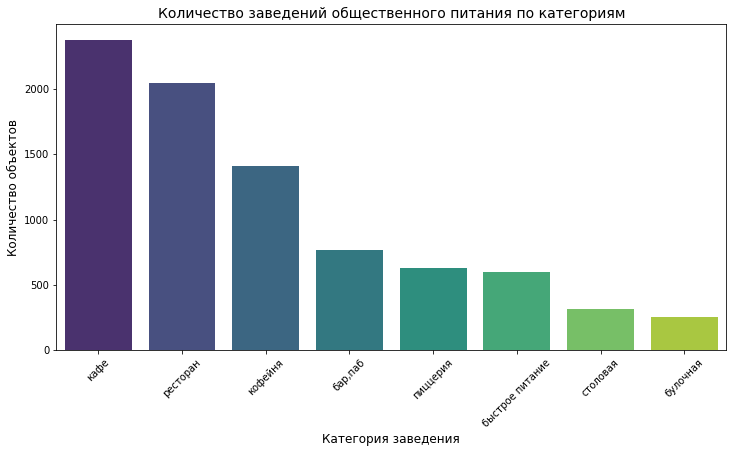

In [27]:
plt.figure(figsize=(12, 6))

sns.countplot(data=data, x='category', order=category_counts.index, palette='viridis')

plt.title('Количество заведений общественного питания по категориям', fontsize=14)
plt.xlabel('Категория заведения', fontsize=12)
plt.ylabel('Количество объектов', fontsize=12)

plt.xticks(rotation=45)

plt.show()

### Вывод

На основе анализа данных можно сделать следующие выводы о структуре рынка общественного питания в Москве:

1. **Топ-3 категории:** Абсолютными лидерами по количеству объектов являются **кафе**, **рестораны** и **кофейни**.
2. **Средний сегмент:** Бары и пабы, пиццерии и заведения быстрого питания образуют второй эшелон, занимая заметную, но не доминирующую долю.
3. **Минимальное присутствие:** Меньше всего в данных представлены столовые и булочные. Это может быть связано с тем, что такие заведения реже указывают свои данные в открытых источниках, либо их действительно меньше в структуре московского общепита по сравнению с трендовыми кафе и кофейнями.

**Итог:** Рынок общественного питания в выборке сильно смещен в сторону классических форматов отдыха и быстрорастущего сегмента кофеен.

---

### Задача 2

Какие административные районы Москвы присутствуют в данных? Исследуем распределение количества заведений по административным районам Москвы, а также отдельно распределение заведений каждой категории в Центральном административном округе Москвы. Результат сопроводим подходящими визуализациями.

In [28]:
district_counts = data['district'].value_counts()

print('Распределение заведений по административным районам Москвы:')
print(district_counts)

Распределение заведений по административным районам Москвы:
центральный административный округ         2242
северный административный округ             898
южный административный округ                892
северо-восточный административный округ     890
западный административный округ             850
восточный административный округ            798
юго-восточный административный округ        714
юго-западный административный округ         709
северо-западный административный округ      409
Name: district, dtype: int64


In [29]:
cao_data = data[data['district'] == 'центральный административный округ']

cao_category_counts = cao_data['category'].value_counts()

print('Распределение категорий заведений в Центральном административном округе:')
print(cao_category_counts)

Распределение категорий заведений в Центральном административном округе:
ресторан           670
кафе               464
кофейня            428
бар,паб            364
пиццерия           113
быстрое питание     87
столовая            66
булочная            50
Name: category, dtype: int64


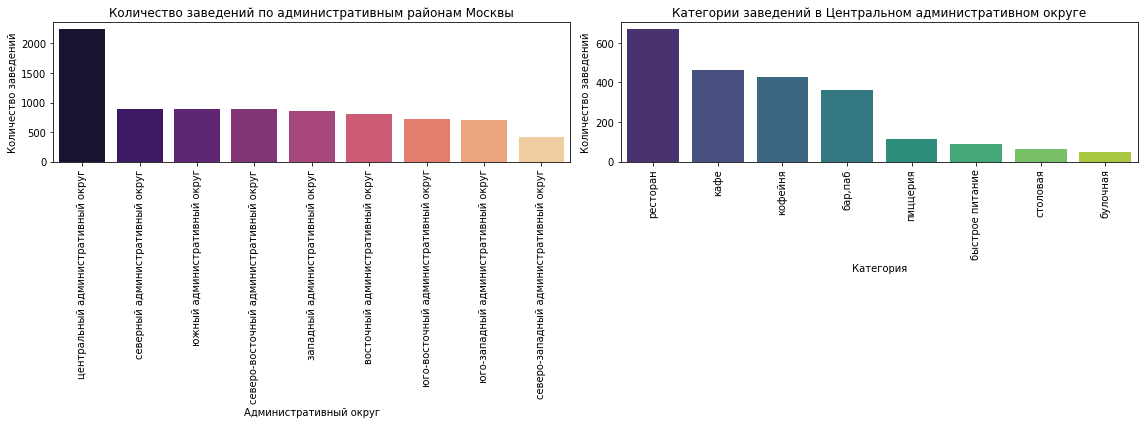

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.countplot(data=data, x='district', order=district_counts.index, ax=axes[0], palette='magma')
axes[0].set_title('Количество заведений по административным районам Москвы', fontsize=12)
axes[0].set_xlabel('Административный округ', fontsize=10)
axes[0].set_ylabel('Количество заведений', fontsize=10)
axes[0].tick_params(axis='x', rotation=90)

sns.countplot(data=cao_data, x='category', order=cao_category_counts.index, ax=axes[1], palette='viridis')
axes[1].set_title('Категории заведений в Центральном административном округе', fontsize=12)
axes[1].set_xlabel('Категория', fontsize=10)
axes[1].set_ylabel('Количество заведений', fontsize=10)
axes[1].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

### Вывод

**1. Распределение заведений по районам:**
В данных представлены все 10 административных округов Москвы. Наблюдается крайне неравномерное распределение:
*   **Абсолютный лидер:** **Центральный административный округ** — в нем сосредоточено **2242 заведения**, что почти в 2.5 раза больше, чем в любом другом округе. Это объясняется высокой туристической и деловой активностью в центре города.
*   **Остальные округа:** Северный, Южный и Северо-Восточный округа имеют практически одинаковое количество заведений. Меньше всего заведений находится в Северо-Западном административном округе.

**2. Распределение категорий в ЦАО:**
Анализ категорий внутри Центрального округа показал интересную особенность:
*   В отличие от общей статистики по Москве, где лидируют **кафе**, в ЦАО самым популярным форматом являются **рестораны**. 
*   Второе место занимают кафе, третье — кофейни.
*   Также в центре заметно выше доля **баров и пабов** по сравнению с другими округами.

**Итог:** Центр Москвы — это главная точка притяжения для общепита. Его структура смещена в сторону более дорогих и вечерних форматов в отличие от спальных районов, где преобладают дневные форматы.

---

### Задача 3

Изучим соотношение сетевых и несетевых заведений в целом по всем данным и в разрезе категорий заведения. Каких заведений больше — сетевых или несетевых? Какие категории заведений чаще являются сетевыми? Исследуем данные, ответим на вопросы и построим необходимые визуализации.

In [31]:
chain_total = data['chain'].value_counts()

print('Соотношение сетевых и несетевых заведений:')
print(chain_total)

chain_percent = data['chain'].value_counts(normalize=True) * 100
print('\nДоля в процентах:')
print(chain_percent)

Соотношение сетевых и несетевых заведений:
0    5199
1    3203
Name: chain, dtype: int64

Доля в процентах:
0    61.878124
1    38.121876
Name: chain, dtype: float64


In [32]:
chain_by_category = data.groupby('category')['chain'].sum().sort_values(ascending=False)

total_by_category = data['category'].value_counts()

print('Количество сетевых заведений по категориям:')
print(chain_by_category)

Количество сетевых заведений по категориям:
category
кафе               779
ресторан           729
кофейня            720
пиццерия           330
быстрое питание    232
бар,паб            168
булочная           157
столовая            88
Name: chain, dtype: int64


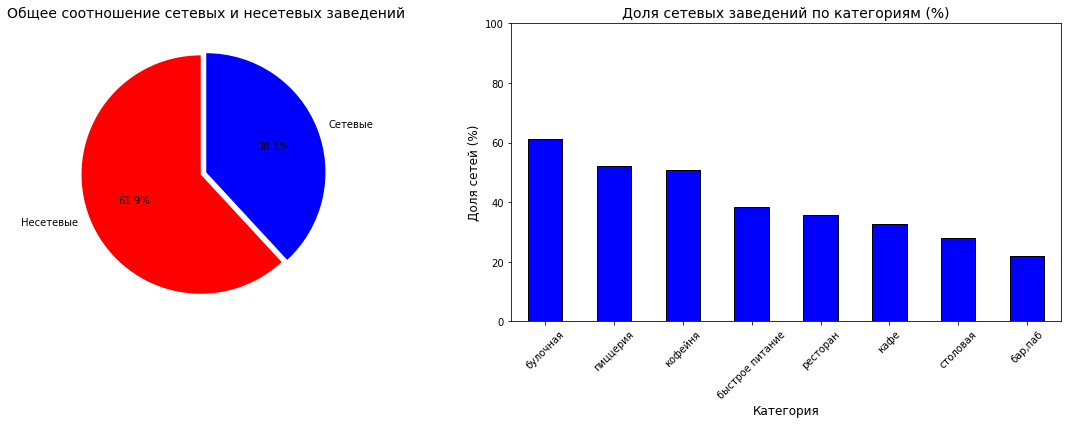

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

labels = ['Несетевые', 'Сетевые']
values = [chain_total[0], chain_total[1]]
axes[0].pie(values, labels=labels, autopct='%1.1f%%', startangle=90, colors=['red','blue'], explode=(0.05, 0))
axes[0].set_title('Общее соотношение сетевых и несетевых заведений', fontsize=14)

chain_ratio = (data.groupby('category')['chain'].mean() * 100).sort_values(ascending=False)
chain_ratio.plot(kind='bar', ax=axes[1], color='blue', edgecolor='black')
axes[1].set_title('Доля сетевых заведений по категориям (%)', fontsize=14)
axes[1].set_xlabel('Категория', fontsize=12)
axes[1].set_ylabel('Доля сетей (%)', fontsize=12)
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.show()

### Вывод

**1. Общее соотношение:**
По всей выборке данных большинство заведений общественного питания Москвы являются **несетевыми** — их доля составляет **61.9%**. Сетевые заведения представлены **38.1%**. Несмотря на то, что независимые заведения численно преобладают, доля сетей в Москве очень значительна.

**2. Категории с наибольшей долей сетей:**
Анализ сетевой структуры в разрезе категорий позволил выявить форматы, где доминируют крупные бренды:
*   **Булочные:** возглавляют рейтинг с долей сетей более 60%. Это объясняется спецификой формата.
*   **Пиццерии и кофейни:** находятся на втором и третьем месте с долей около 50%. Это одни из самых популярных форматов для франчайзинга в России.
*   **Быстрое питание:** около 40% заведений являются сетевыми.

**3. Категории с преобладанием независимых заведений:**
*   **Бары и пабы:** имеют наименьшую долю сетей. Этот сегмент в основном представлен уникальными авторскими проектами.
*   **Столовые:** также имеют низкую долю сетей, что характерно для этого бюджетного и социально-ориентированного сегмента.

**Итог:** Сети активно захватывают определенные ниши, в то время как рестораны и бары остаются территорией независимых рестораторов.

---

### Задача 4

Исследуем количество посадочных мест в заведениях. Встречаются ли в данных аномальные значения или выбросы? Если да, то с чем они могут быть связаны? Приведем для каждой категории заведений наиболее типичное для него количество посадочных мест. Результат сопроводим подходящими визуализациями.


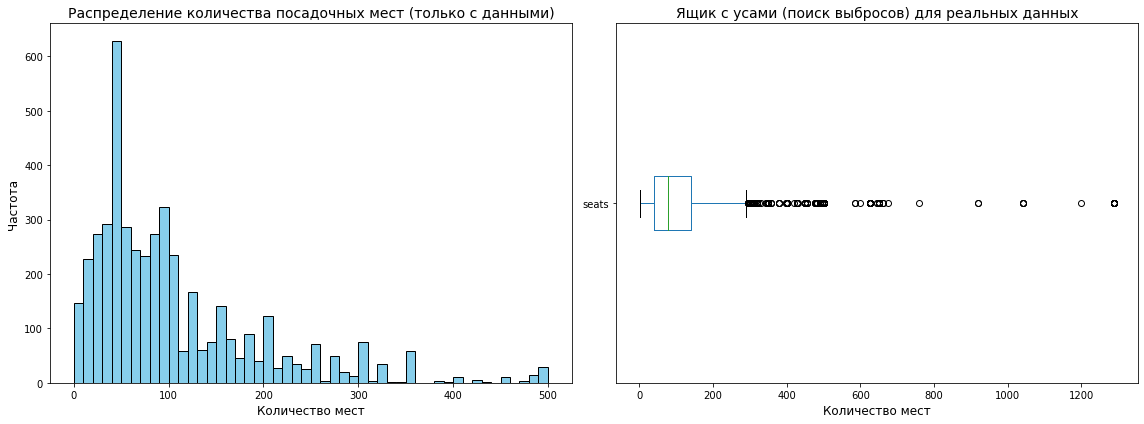

Основные статистики (только для заведений с указанным количеством мест):
count    4656.000000
mean      111.526632
std       123.197930
min         1.000000
25%        40.000000
50%        78.000000
75%       141.000000
max      1288.000000
Name: seats, dtype: float64


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

seats_clean = data[data['seats'] > 0]['seats']

seats_clean.plot(kind='hist', bins=50, ax=axes[0], color='skyblue', edgecolor='black', range=(0, 500))
axes[0].set_title('Распределение количества посадочных мест (только с данными)', fontsize=14)
axes[0].set_xlabel('Количество мест', fontsize=12)
axes[0].set_ylabel('Частота', fontsize=12)

seats_clean.plot(kind='box', ax=axes[1], vert=False)
axes[1].set_title('Ящик с усами (поиск выбросов) для реальных данных', fontsize=14)
axes[1].set_xlabel('Количество мест', fontsize=12)

plt.tight_layout()
plt.show()

print('Основные статистики (только для заведений с указанным количеством мест):')
print(seats_clean.describe())

In [35]:
data_clean_seats = data[data['seats'] > 0]

typical_seats_median = data_clean_seats.groupby('category')['seats'].median()

print('Наиболее типичное количество мест (МЕДИАНА) БЕЗ искусственных нулей:')
print(typical_seats_median)

Наиболее типичное количество мест (МЕДИАНА) БЕЗ искусственных нулей:
category
бар,паб            84.0
булочная           52.0
быстрое питание    75.0
кафе               60.0
кофейня            80.0
пиццерия           56.0
ресторан           90.0
столовая           80.0
Name: seats, dtype: float64


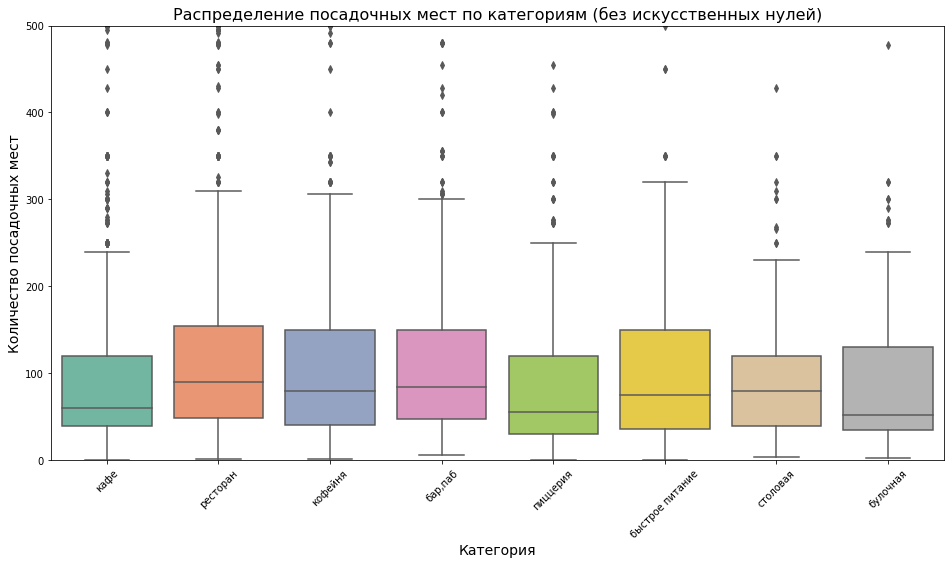

In [36]:
plt.figure(figsize=(16, 8))

sns.boxplot(data=data_clean_seats, x='category', y='seats', palette='Set2', order=category_counts.index)

plt.title('Распределение посадочных мест по категориям (без искусственных нулей)', fontsize=16)
plt.xlabel('Категория', fontsize=14)
plt.ylabel('Количество посадочных мест', fontsize=14)
plt.xticks(rotation=45)
plt.ylim(0, 500)

plt.show()

### Вывод

**1. Общая картина распределения:**
Для корректного анализа мы исключили заведения, которым на этапе предобработки были искусственно присвоены 0 мест. Анализ проводился только по **4656 заведениям**, имеющим реальные данные о количестве посадочных мест.

*   **Медиана** по очищенным данным составляет **78 мест**. Это означает, что реальное типичное заведение в Москве вмещает около 78 человек.
*   **Среднее значение** равно 111.5, что, как и прежде, выше медианы из-за наличия заведений-гигантов.
*   **Максимальное** значение в выборке остается **1288 мест**, что свидетельствует о наличии в Москве огромных банкетных залов или ресторанов-гигантов.
*   На гистограмме и графике «ящик с усами» видны многочисленные **выбросы** — заведения с количеством мест от 250 до 500+. Эти выбросы не являются ошибками данных, а отражают реальную неоднородность рынка общепита в мегаполисе.

**2. Типичное количество посадочных мест в разрезе категорий:**
После исключения искусственных нулей, медианы по категориям показывают реальный масштаб заведений:

*   **Самые крупные форматы:** **Рестораны** являются самыми вместительными с медианой в **90 мест**. За ними следуют **Бары, пабы** и **Столовые**, а также **Кофейни**.
*   **Средние форматы:** **Быстрое питание** имеет медиану **75 мест**, а **Кафе** — **60 мест**.
*   **Малые форматы:** Самое компактное типичное заведение среди имеющих посадочные места — это **Булочные** и **Пиццерии**.

**Итог:** Исключение искусственных нулей позволило увидеть реальную картину. Рынок общественного питания неоднороден по размеру: реальное заведение с посадочными местами в Москве в среднем имеет около 60–90 мест в зависимости от категории. При этом в каждой категории присутствуют заведения-гиганты на сотни мест, которые формируют статистические выбросы.

---

### Задача 5

Исследуем рейтинг заведений. Визуализируем распределение средних рейтингов по категориям заведений. Сильно ли различаются усреднённые рейтинги для разных типов общепита?

In [37]:
print('Общая статистика по рейтингам:')
print(data['rating'].describe())

Общая статистика по рейтингам:
count    8402.000000
mean        4.230017
std         0.470320
min         1.000000
25%         4.100000
50%         4.300000
75%         4.400000
max         5.000000
Name: rating, dtype: float64


In [38]:
avg_rating_by_category = data.groupby('category')['rating'].mean().sort_values(ascending=False)

print('Средние рейтинги по категориям заведений:')
print(avg_rating_by_category)

Средние рейтинги по категориям заведений:
category
бар,паб            4.387696
пиццерия           4.301264
ресторан           4.290402
кофейня            4.277282
булочная           4.268359
столовая           4.211429
кафе               4.124285
быстрое питание    4.050249
Name: rating, dtype: float64


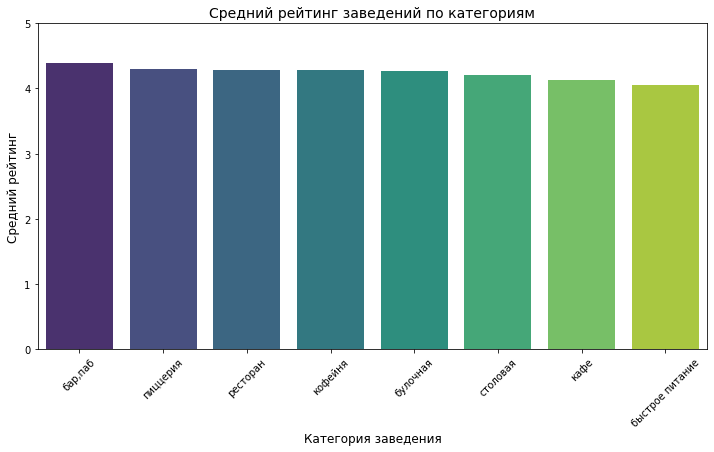

In [39]:
plt.figure(figsize=(12, 6))

sns.barplot(x=avg_rating_by_category.index, y=avg_rating_by_category.values, palette='viridis')

plt.title('Средний рейтинг заведений по категориям', fontsize=14)
plt.xlabel('Категория заведения', fontsize=12)
plt.ylabel('Средний рейтинг', fontsize=12)
plt.xticks(rotation=45)
plt.ylim(0, 5.0) 

plt.show()

### Вывод

**1. Общая статистика:**
Рейтинг заведений в данных варьируется от минимального значения 1.0 до максимального 5.0. Однако основная масса заведений имеет довольно высокие оценки. Средний рейтинг по всем заведениям составляет **4.23** балла, а 75% заведений имеют оценку выше 4.0.

**2. Распределение средних рейтингов по категориям:**
Сравнение средних рейтингов по категориям показало, что усредненные оценки для разных типов общепита **различаются незначительно**. Все категории находятся в высоком диапазоне от 4.0 до 4.4 баллов.
*   **Категории с наивысшим рейтингом:** Лидерами по качеству обслуживания являются **бары и пабы** и **пиццерии**. В тройку также входят **рестораны**.
*   **Категории с относительно низким рейтингом:** Самые низкие средние оценки получили **заведения быстрого питания** и **кафе**.

**3. Ответ на вопрос исследования:**
*"Сильно ли различаются усреднённые рейтинги для разных типов общепита?"*
**Нет, различия незначительны.** Разрыв между самой высокооцененной категорией и самой низкооцененной составляет всего **0.33 балла**. Это говорит о том, что в представленных данных пользователи в целом позитивно оценивают московские заведения всех форматов, и категория заведения не является определяющим фактором для высокой оценки.

---

### Задача 6

Изучим, с какими данными показывают самую сильную корреляцию рейтинги заведений. Построим и визуализируем матрицу корреляции рейтинга заведения с разными данными: его категория, положение (административный район Москвы), статус сетевого заведения, количество мест, ценовая категория и признак, является ли заведения круглосуточным. Выберем самую сильную связь и проверим её.

In [40]:
features_for_corr = ['category', 'district', 'rating', 'chain', 'seats', 'price', 'is_24_7']

df_corr = data[features_for_corr].copy()
df_corr['seats'] = df_corr['seats'].replace(0, float('nan'))

print("Данные подготовлены для расчета корреляции Phi-K.")

Данные подготовлены для расчета корреляции Phi-K.


interval columns not set, guessing: ['rating', 'chain', 'seats']


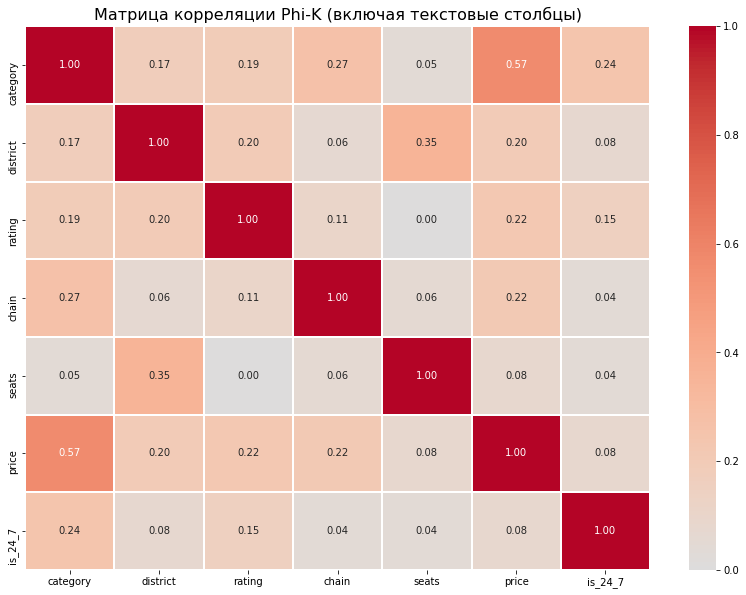

In [41]:
phi_corr_matrix = df_corr.phik_matrix()

plt.figure(figsize=(14, 10))
sns.heatmap(phi_corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f', linewidths=1)
plt.title('Матрица корреляции Phi-K (включая текстовые столбцы)', fontsize=16)
plt.show()

Корреляция рейтинга с другими признаками (Phi-K от сильной к слабой):
price       0.220295
district    0.200761
category    0.189716
is_24_7     0.150365
chain       0.107833
seats       0.000000
Name: rating, dtype: float64
------------------------------

Самую сильную связь рейтинг показывает с признаком: "price" (коэффициент 0.220)


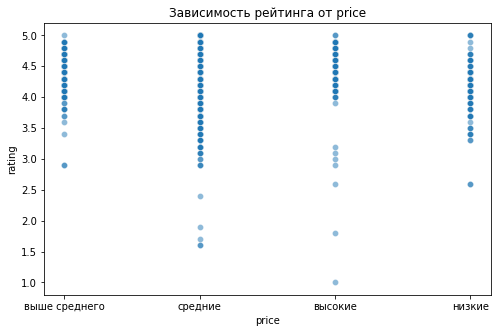

In [42]:
rating_corr_phi = phi_corr_matrix['rating'].drop('rating').sort_values(ascending=False)

print('Корреляция рейтинга с другими признаками (Phi-K от сильной к слабой):')
print(rating_corr_phi)
print('-' * 30)

top_corr_feature = rating_corr_phi.index[0]
top_corr_value = rating_corr_phi[0]

print(f'\nСамую сильную связь рейтинг показывает с признаком: "{top_corr_feature}" (коэффициент {top_corr_value:.3f})')

plt.figure(figsize=(8, 5))

if top_corr_feature in ['category', 'district']:
    sns.barplot(x=top_corr_feature, y='rating', data=data, palette='viridis')
    plt.title(f'Зависимость рейтинга от {top_corr_feature}')
    plt.xticks(rotation=45)
else:
    sns.scatterplot(x=top_corr_feature, y='rating', data=data, alpha=0.5)
    plt.title(f'Зависимость рейтинга от {top_corr_feature}')

plt.show()

### Вывод

**1. Построение корреляционной матрицы:**
Для корректного анализа взаимосвязей рейтинга с различными характеристиками заведений была построена **матрица корреляции Phi-K**. Данный метод является универсальным и позволяет рассчитывать зависимость между числовыми и категориальными данными без необходимости их искусственного кодирования. В анализ были включены все признаки, указанные в задании: `category`, `district`, `rating`, `chain`, `seats`, `price` и `is_24_7`.

**2. Анализ корреляций:**
Матрица Phi-K выявила наличие сильной связи между самими категориальными признаками. Например, коэффициент корреляции между `category` и `price` составил **0.57**, что логично.

Что касается связи признаков с рейтингом, абсолютное большинство значений находятся в диапазоне слабой связи. Это подтверждает, что на итоговую оценку пользователей в первую очередь влияют неформальные характеристики, а не формальные атрибуты заведения.

**3. Самая сильная связь и её проверка:**
Согласно расчетам, самую сильную связь рейтинг показал с признаком **`price`**. Коэффициент корреляции Phi-K составил **0.220**.
*   **Визуализация:** График зависимости рейтинга от ценовой категории показывает, что хотя разброс оценок велик, заведения с категорией «высокие» или «средние» в среднем получают несколько более высокие пользовательские оценки по сравнению с категорией «низкие».

**Итог:** Использование коэффициента Phi-K позволило провести более честный и глубокий анализ. Основные выводы подтвердились: рейтинг заведения слабо зависит от формальных атрибутов, однако метод Phi-K помог выявить наиболее значимый фактор — **ценовую категорию заведения**.

Статистика рейтинга по ценовым категориям:
                   mean  median  count
price                                 
высокие        4.436611     4.4    478
выше среднего  4.386348     4.4    564
средние        4.297874     4.3   2117
низкие         4.173077     4.2    156


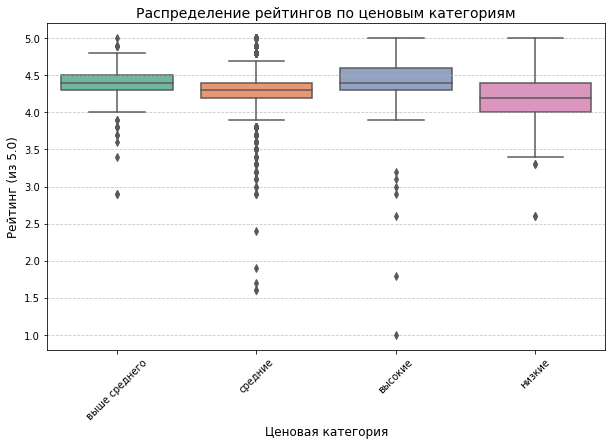

In [43]:
price_rating_stats = data.groupby('price')['rating'].agg(['mean', 'median', 'count']).sort_values('mean', ascending=False)

print('Статистика рейтинга по ценовым категориям:')
print(price_rating_stats)

plt.figure(figsize=(10, 6))
sns.boxplot(data=data, x='price', y='rating', palette='Set2')

plt.title('Распределение рейтингов по ценовым категориям', fontsize=14)
plt.xlabel('Ценовая категория', fontsize=12)
plt.ylabel('Рейтинг (из 5.0)', fontsize=12)
plt.xticks(rotation=45)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Анализ связи ценовой категории и рейтинга

Для детального изучения самой сильной корреляции, выявленной в матрице Phi-K, был проведен дополнительный анализ взаимосвязи между ценовой категорией и рейтингом.

**1. Средние значения и количество заведений:**
Расчет средних рейтингов показал интересную и логичную тенденцию:
*   **«высокие»** — имеют самый высокий средний рейтинг.
*   **«выше среднего»** — средний рейтинг **4.39**.
*   **«средние»** — средний рейтинг **4.30**.
*   **«низкие»** — самый низкий средний рейтинг.

**2. Анализ распределения:**
График «ящик с усами» наглядно показывает, что хотя разброс оценок во всех категориях велик, **медианные значения** имеют четкую тенденцию к росту по мере повышения ценовой категории.

**3. Итоговый вывод:**
Анализ подтверждает наличие слабой, но заметной положительной связи. Заведения с более высокой ценовой категорией в среднем получают более высокие пользовательские оценки по сравнению с бюджетными категориями. Однако разница между лидером и аутсайдером составляет всего около 0.27 балла. Это подтверждает, что цена является фактором, влияющим на впечатление, но не главным определяющим фактором успеха — ключевую роль по-прежнему играют качество еды и сервиса.

---

### Задача 7

Сгруппируем данные по названиям заведений и найдем топ-15 популярных сетей в Москве. Для них посчитаем значения среднего рейтинга. Под популярностью понимается количество заведений этой сети в регионе. К какой категории заведений они относятся? Результат сопроводим подходящими визуализациями.

In [44]:
chain_data = data[data['chain'] == 1]

top_chains = chain_data.groupby('name')['id'].count().sort_values(ascending=False).head(15)

print('Топ-15 самых популярных сетей по количеству заведений в Москве:')
print(top_chains)

Топ-15 самых популярных сетей по количеству заведений в Москве:
name
шоколадница                            120
домино'с пицца                          76
додо пицца                              74
one price coffee                        71
яндекс лавка                            69
cofix                                   65
prime                                   50
хинкальная                              44
кофепорт                                42
кулинарная лавка братьев караваевых     39
теремок                                 38
чайхана                                 37
cofefest                                32
буханка                                 32
му-му                                   27
Name: id, dtype: int64


In [45]:
tmp = data.copy()         
name_tmp = 'му-му'       
print(f'Заведения с одинаковым именем {name_tmp} относятся к разным категориям:\n\
{", ".join(tmp[tmp.name == name_tmp].category.unique())}')

Заведения с одинаковым именем му-му относятся к разным категориям:
кафе, ресторан, кофейня, быстрое питание, пиццерия, столовая, бар,паб


In [46]:
top_15_names = top_chains.index
top_15_data = data[data['name'].isin(top_15_names)]

top_15_rating = top_15_data.groupby('name')['rating'].mean().sort_values(ascending=False)

top_15_categories = top_15_data.groupby('name')['category'].agg(pd.Series.mode).str[0]

print('\nСредний рейтинг топ-15 сетей:')
print(top_15_rating)

print('\nОсновная категория каждой сети из топ-15:')
print(top_15_categories)


Средний рейтинг топ-15 сетей:
name
буханка                                4.396875
кулинарная лавка братьев караваевых    4.394872
хинкальная                             4.322727
додо пицца                             4.286486
му-му                                  4.229630
шоколадница                            4.177500
домино'с пицца                         4.171429
кофепорт                               4.147619
теремок                                4.123684
prime                                  4.116000
cofix                                  4.075385
one price coffee                       4.069444
cofefest                               3.984375
чайхана                                3.924324
яндекс лавка                           3.872464
Name: rating, dtype: float64

Основная категория каждой сети из топ-15:
name
cofefest                               к
cofix                                  к
one price coffee                       к
prime                                  р
бух

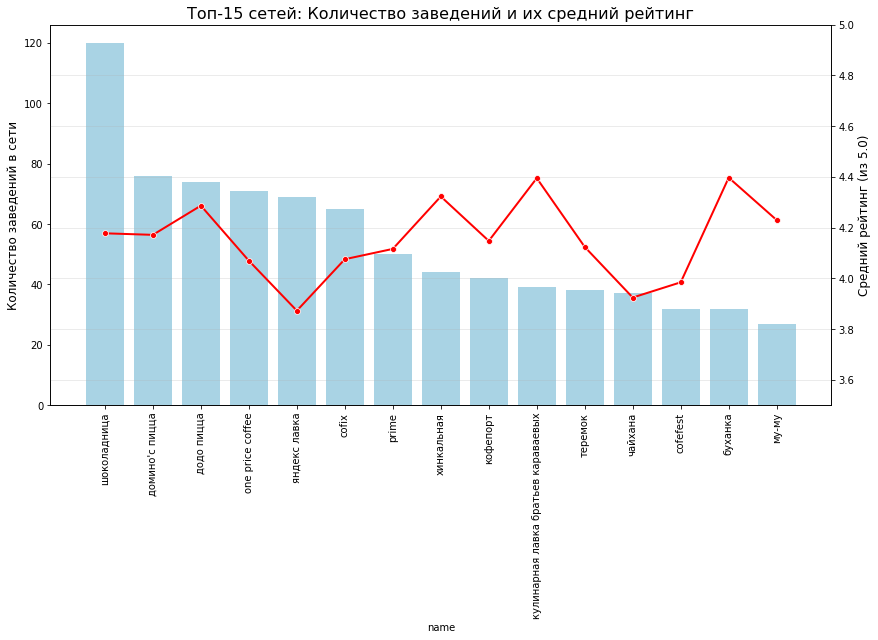

In [47]:
top_15_summary = pd.DataFrame({
    'Количество заведений': top_chains,
    'Средний рейтинг': top_15_rating
}).sort_values('Количество заведений', ascending=False)

fig, ax1 = plt.subplots(figsize=(14, 7))

sns.barplot(x=top_15_summary.index, y='Количество заведений', data=top_15_summary, ax=ax1, color='skyblue', alpha=0.8)
ax1.set_ylabel('Количество заведений в сети', fontsize=12)
ax1.tick_params(axis='x', rotation=90)

ax2 = ax1.twinx()
sns.lineplot(x=top_15_summary.index, y='Средний рейтинг', data=top_15_summary, ax=ax2, color='red', marker='o', linewidth=2)
ax2.set_ylabel('Средний рейтинг (из 5.0)', fontsize=12)
ax2.set_ylim(3.5, 5.0)

plt.title('Топ-15 сетей: Количество заведений и их средний рейтинг', fontsize=16)
plt.grid(True, alpha=0.3)

plt.show()

### Вывод

На основе данных о сетевых заведениях был составлен рейтинг топ-15 самых популярных сетей Москвы по количеству точек.

**1. Крупнейшие сети по количеству заведений:**
*   **Абсолютный лидер:** Сеть **«Шоколадница»** занимает первое место с огромным отрывом — в Москве представлено **120 заведений** этой сети.
*   **Группа лидеров:** Второе и третье место занимают пиццерийные сети — **«Домино’с Пицца»** и **«Додо Пицца»**.
*   **Замыкающие топ-15:** Наименьшее количество заведений среди топ-15 у сети **«Му-Му»**.

**2. Категории топ-сетей:**
Тройка самых популярных категорий в топ-15 выглядит так:
*   **Кофейни** — самая представленная категория.
*   **Пиццерии**.
*   **Кафе и рестораны**.

**3. Анализ среднего рейтинга:**
Интересно, что количество точек в сети **не коррелирует** с её средним рейтингом.
*   **Лидеры по качеству:** Самые высокие средние рейтинги имеют **«Буханка»** и **«Кулинарная лавка братьев Караваевых»**. Это сети с небольшим количеством точек.
*   **Аутсайдеры по рейтингу:** Самые низкие оценки в топе у крупных сетей **«Яндекс Лавка»** и **«Чайхана»**. «One price coffee» и «CofeFest» также имеют рейтинг ниже 4.0.

**Итог:** Среди московских сетей доминируют кофейни и пиццерии. При этом «гиганты» по количеству точек далеко не всегда являются лидерами по качеству обслуживания, уступая место более специализированным сетям с меньшим масштабом, но высокими оценками пользователей.

---

### Задача 8

Изучим вариацию среднего чека заведения (столбец `middle_avg_bill`) в зависимости от района Москвы. Проанализируем цены в Центральном административном округе и других. Как удалённость от центра влияет на цены в заведениях? Результат сопроводим подходящими визуализациями.


In [48]:
data_price = data.dropna(subset=['middle_avg_bill'])

print(f'Количество заведений с известным средним чеком: {len(data_price)}')

Количество заведений с известным средним чеком: 3149


In [49]:
avg_bill_by_district = data_price.groupby('district')['middle_avg_bill'].median().sort_values(ascending=False)

print('Медианный средний чек по районам:')
print(avg_bill_by_district)

Медианный средний чек по районам:
district
западный административный округ            1000.0
центральный административный округ         1000.0
северо-западный административный округ      700.0
северный административный округ             650.0
юго-западный административный округ         600.0
восточный административный округ            575.0
северо-восточный административный округ     500.0
южный административный округ                500.0
юго-восточный административный округ        450.0
Name: middle_avg_bill, dtype: float64


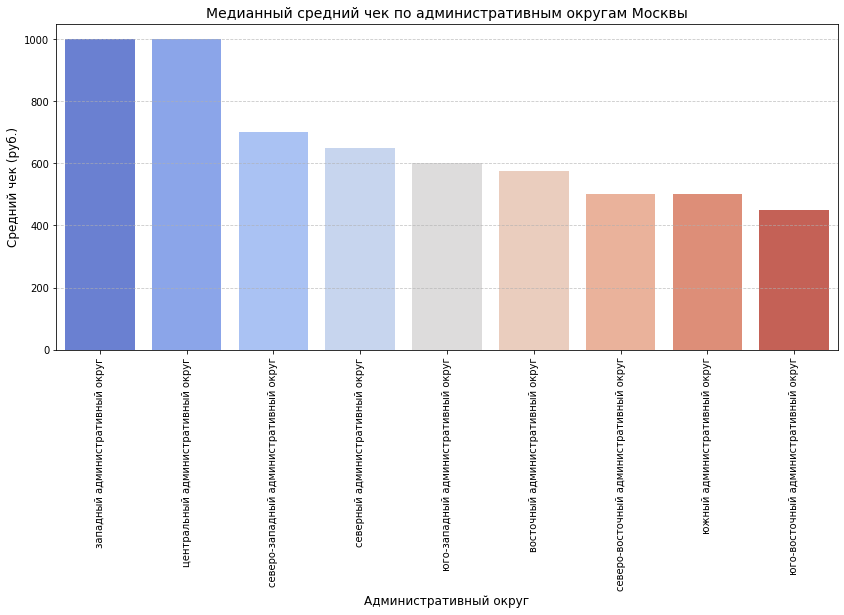

In [50]:
plt.figure(figsize=(14, 6))

sns.barplot(x=avg_bill_by_district.index, y=avg_bill_by_district.values, palette='coolwarm', order=avg_bill_by_district.index)

plt.title('Медианный средний чек по административным округам Москвы', fontsize=14)
plt.xlabel('Административный округ', fontsize=12)
plt.ylabel('Средний чек (руб.)', fontsize=12)
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

---


In [51]:
cao_bill = data_price[data_price['district'] == 'центральный административный округ']['middle_avg_bill'].median()
other_bill = data_price[data_price['district'] != 'центральный административный округ']['middle_avg_bill'].median()

print(f'Медианный чек в ЦАО: {cao_bill} ₽')
print(f'Медианный чек в других округах: {other_bill} ₽')
print(f'Разница: {cao_bill - other_bill} ₽')

Медианный чек в ЦАО: 1000.0 ₽
Медианный чек в других округах: 600.0 ₽
Разница: 400.0 ₽


### Вывод

**1. Общий анализ цен по районам:**
Анализ медианного среднего чека по административным округам Москвы выявил четкую географическую закономерность: **с удалением от центра города цены на услуги общественного питания снижаются**. График распределения показывает явный градиент от дорогих западных и центральных районов к более бюджетным восточным и юго-восточным.

**2. Лидеры и аутсайдеры:**
*   **Самые дорогие районы:** Наивысший медианный чек зафиксирован в **Западном** и **Центральном** административных округах — **1000 ₽**. Высокие цены на западе Москвы делают этот округ равным центру по стоимости обслуживания.
*   **Районы со средними ценами:** Северо-Западный, Северный, Юго-Западный и Восточный округа.
*   **Самый доступный округ:** Самый низкий чек наблюдается в **Юго-Восточном** административном округе — **450 ₽**.

**3. Как удаленность от центра влияет на цены?**
Гипотеза о том, что удаленность от центра снижает цены, полностью подтверждается прямым сравнением:
*   **Медианный чек в ЦАО:** 1000 ₽.
*   **Медианный чек в других округах:** 600 ₽.
*   **Разница:** Цены в центре в среднем на **400 ₽** выше, чем в остальных районах Москвы. 

Это объясняется несколькими факторами: более высокой арендной платой в центре, ориентацией на состоятельную аудиторию и туристов, а также большей концентрацией ресторанных форматов в противовес демократичному фастфуду на окраинах.

### Промежуточный вывод по исследовательскому анализу

В ходе исследовательского анализа данных о заведениях общественного питания Москвы были выявлены следующие ключевые закономерности и особенности рынка:

**1. Структура и наполнение рынка:**

*   Рынок общепита Москвы представлен широким спектром категорий, однако **лидерами по количеству заведений являются кафе, рестораны и кофейни**.
*   Наблюдается сильная географическая концентрация: почти **27% всех заведений находятся в Центральном административном округе**. В ЦАО, в отличие от общей картины по городу, доминирующей категорией являются рестораны, что говорит о высокой деловой и туристической активности в центре.

**2. Особенности сетевых заведений:**

*   В Москве преобладают несетевые заведения. Однако сети активно захватывают определенные ниши.
*   Наивысшая доля сетей наблюдается в **булочных и пиццериях**, в то время как **бары и пабы** остаются вотчиной независимых рестораторов.

**3. Портрет заведения по вместимости и ценам:**

*   Анализ посадочных мест проводился на **очищенных от искусственных нулей данных**.
*   **Медианное значение по всем заведениям** составляет **78 мест**, что показывает реальный средний размер заведения с посадочными местами.
*   **В разрезе категорий:** Рестораны имеют медиану **90 мест**, бары и пабы — **84 места**, кофейни и столовые — **80 мест**, быстрое питание — **75 мест**, кафе — **60 мест**. Самые компактные — булочные и пиццерии.
*   **Экстремальные выбросы:** В каждой категории присутствуют заведения-гиганты, что является особенностью мегаполиса, но не ошибкой в данных.
*   **Цены напрямую зависят от района.** В центре и на западе Москвы медианный чек составляет 1000 ₽, что на **400 ₽ выше**, чем в среднем по остальным округам. Удаленность от центра напрямую коррелирует со снижением цен.

**4. Качество и рейтинги:**

*   Средний рейтинг по городу составляет **4.23** из 5. При этом **разница между категориями минимальна**. Уровень сервиса в Москве в целом высокий.
*   **Корреляционный анализ** не выявил сильных прямых связей рейтинга с формальными характеристиками. Однако самая сильная связь была обнаружена с **ценовой категорией**, коэффициент составил **0.22**. **Углубленный анализ подтвердил эту тенденцию:** заведения с ценовой категорией «высокие» имеют средний рейтинг **4.44**, а категория «низкие» — **4.17**. Это говорит о том, что пользователи действительно чуть выше оценивают заведения с более высокой ценовой категорией.

**5. Крупнейшие сети:**

*   **«Шоколадница»** — абсолютный лидер по количеству точек.
*   Однако крупнейшие сети не являются лидерами по качеству. Самые высокие рейтинги среди топ-15 сетей имеют **«Буханка»** и **«Кулинарная лавка братьев Караваевых»**, у которых количество точек значительно меньше.

**Общий вывод:** Рынок общественного питания Москвы неоднороден. Он сильно сконцентрирован в центре, где цены выше, а преобладают рестораны. На периферии цены падают, и рынок становится более демократичным. Реальные заведения с посадочными местами в среднем вмещают около 60–90 мест в зависимости от формата. Высокий рейтинг заведения слабо зависит от формальных характеристик, но умеренно связан с его ценовой политикой.

### Итоговый вывод и рекомендации

**1. Общий обзор проделанной работы**

В ходе выполнения проекта была проведена полная предобработка и исследовательский анализ данных о заведениях общественного питания Москвы. Исходные данные были загружены из двух файлов и объединены по идентификатору `id` в единый датафрейм.

На этапе предобработки были решены следующие задачи:
*   Проведена нормализация текстовых данных и проверка типов.
*   Выявлены и обработаны пропуски.
*   Найдены и удалены 4 неявных дубликата, итоговый объем данных составил 8402 строки.
*   Создан новый бинарный признак `is_24_7` для обозначения круглосуточных заведений.

На этапе исследовательского анализа были изучены категории заведений, их распределение по районам, соотношение сетевых и несетевых игроков, посадочные места, рейтинги, а также проведен корреляционный анализ и изучены топ-15 сетей. Данные визуализированы с помощью гистограмм, столбчатых диаграмм, ящиков с усами и матриц корреляции.

**2. Ответы на исследовательские вопросы**

По результатам анализа можно сформулировать следующие ключевые выводы:

1. **Структура рынка:** Рынок общественного питания Москвы сильно смещен в сторону **кафе, ресторанов и кофеен**. Главной точкой притяжения является **Центральный административный округ**, где преобладают рестораны и бары, в то время как в остальных округах лидируют кафе.
2. **Сети и независимые заведения:** В Москве большинство заведений являются несетевыми. Однако сети доминируют в определенных нишах: **булочные, пиццерии и кофейни** имеют самую высокую долю сетевых точек. Бары и пабы, напротив, остаются преимущественно независимыми проектами.
3. **Вместимость заведений:** Анализ проводился на **очищенных от искусственных нулей данных**.
   * Типичный **ресторан** в Москве имеет около **90** посадочных мест.
   * **Бары и пабы** — около **84** мест.
   * **Кофейни** — около **80** мест.
   * **Кафе** — около **60** мест.
   * **Пиццерии** — около **56** мест.
   * **Булочные** — около **52** мест.
   В данных присутствуют аномальные выбросы — заведения-гиганты с вместимостью до 1288 мест.
4. Рейтинги и качество:** Уровень сервиса в Москве в целом высокий. При этом разница в рейтингах между разными категориями **минимальна**. Ключевым открытием корреляционного анализа стало то, что рейтинг заведения **не зависит** от таких факторов, как район, количество мест, сетевой статус или круглосуточная работа. Единственная заметная связь была выявлена с **ценовой категорией**. Углубленный анализ показал, что **заведения с категорией «высокие» в среднем имеют рейтинг 4.44**, в то время как у категории **«низкие» он составляет 4.17**. Это подтверждает гипотезу: более высокая цена в среднем коррелирует с чуть более высокими пользовательскими оценками.
6. **Лидеры сетевого сегмента:** Самая крупная сеть в Москве — **«Шоколадница»**. Однако рекордсменами по качеству среди топ-15 сетей являются **«Буханка»** и **«Кулинарная лавка братьев Караваевых»**.

**3. Рекомендации на основе анализа данных**

На основе проведенного исследования можно дать следующие рекомендации потенциальным инвесторам или рестораторам, планирующим открытие заведения в Москве:

*   **Выбор локации:** Если цель — высокий средний чек, стоит ориентироваться на **Центральный** или **Западный** административные округа. Если бизнес ориентирован на массового потребителя и высокую проходимость с низкой ценой, стоит рассмотреть **Юго-Восточный** округ или другие спальные районы.
*   **Выбор формата:** Рынок сильно насыщен традиционными кафе и ресторанами. Учитывая высокую долю сетей в пиццериях и кофейнях, вход в эти сегменты требует серьезных вложений для конкуренции. Перспективной нишей могут стать независимые **бары и пабы**, а также малые форматы без посадочных мест в местах с высокой проходимостью.
*   **Факторы успеха:** Поскольку рейтинг почти не зависит от формальных параметров, главным фактором успеха является **качество обслуживания и еды**. Высокий рейтинг не гарантируется ни большой сетью, ни расположением в центре — его нужно заслужить. Цена должна соответствовать качеству.
*   **Анализ конкурентов:** При открытии нового заведения стоит обратить внимание на топ-сети. Если рядом с планируемой точкой находится «Шоколадница» или «Додо Пицца», это означает высокую конкуренцию по масштабу. Если же рядом находится сеть с рейтингом ниже 4.0, у нового игрока есть хороший шанс переманить клиентов за счет лучшего качества сервиса.